In [ ]:
!pip install -q transformers accelerate bitsandbytes diffusers safetensors scikit-image

In [ ]:
import torch, json, re, os, unicodedata
from PIL import Image
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor
from google.colab import drive

if not getattr(torch.Tensor.prod, "_parcheado", False):
    _prod_original = torch.Tensor.prod
    def _prod_sin_jit(self, *args, **kwargs):
        if self.is_cuda and not self.is_floating_point():
            return _prod_original(self.cpu(), *args, **kwargs).to(self.device)
        return _prod_original(self, *args, **kwargs)
    _prod_sin_jit._parcheado = True
    torch.Tensor.prod = _prod_sin_jit
    print("parche de prod aplicado")

drive.mount("/content/drive")
SALIDA = "/content/drive/MyDrive/resultados etapa 2"
os.makedirs(SALIDA, exist_ok=True)

REAL = "/content/par2.png"
PAR  = "par2"
CALIDAD_JPEG = 94
SEMILLA = 22500

assert os.path.exists(REAL), f"no encuentro {REAL}"
img = Image.open(REAL).convert("RGB")
W, H = img.size

MODELO_VL = "Qwen/Qwen2.5-VL-7B-Instruct"
vl = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODELO_VL, dtype=torch.bfloat16, device_map="cuda")
vl_proc = AutoProcessor.from_pretrained(MODELO_VL)

INSTRUCCION = """Analiza esta fotografía política y propón TRES manipulaciones locales
creíbles como desinformación, sobre objetos de TAMAÑOS CLARAMENTE DISTINTOS.

Responde SOLO con un objeto JSON:
{
  "escena": "descripción breve en español",
  "ediciones": [
    {
      "tamano": "grande" | "mediano" | "pequeno",
      "objeto": "ENGLISH: short noun phrase naming the visible object to edit",
      "cambio": "ENGLISH: noun phrase describing the object AFTER the edit",
      "evitar": "ENGLISH: what must not appear, including the original state",
      "justificacion": "en español: por qué es creíble como desinformación"
    }
  ]
}

REGLAS OBLIGATORIAS:
1. "objeto", "cambio" y "evitar" van EN INGLÉS. Los demás en español.
2. "cambio" es un SINTAGMA NOMINAL que describe el objeto ya editado.
   CORRECTO: "a blue silk necktie", "a framed portrait of a man"
   INCORRECTO: "ser cambiada por una corbata azul", "replace the tie", "change it to blue"
3. PROHIBIDO proponer ediciones sobre caras, cabezas, pelo o manos.
4. NUNCA uses negaciones en "cambio": nada de "instead of", "not", "without".
5. "objeto" debe ser un objeto físico distinguible y específico, porque un detector
   lo va a buscar por esa frase: "red necktie", no "the tie of the man on the left".
6. Los tres tamaños deben ser distintos entre sí:
   grande  = un elemento dominante de la escena (un cuadro grande, un traje completo)
   mediano = un objeto de tamaño medio (un maletín, una planta, una silla)
   pequeno = un detalle (una corbata, un broche, un vaso)

NO clasifiques por dificultad de detección. Solo por tamaño físico del objeto."""

NEGACIONES = ["instead of", " not ", "without", " no "]
VERBOS = ["ser ", "be ", "change", "replace", "make it", "turn into", "convert"]
ESPANOL = ["ser", "una", "por", "cambiada", "reemplazado", "corbata", "cuadro", "que"]
PROHIBIDOS_OBJ = ["face", "head", "hair", "hand", "cara", "rostro", "mano"]

def normaliza(t):
    t = unicodedata.normalize("NFKD", t.lower().strip())
    return "".join(c for c in t if not unicodedata.combining(c))

TAMANOS = {"grande": "grande", "large": "grande", "big": "grande",
           "mediano": "mediano", "medium": "mediano", "media": "mediano",
           "pequeno": "pequeno", "pequena": "pequeno", "small": "pequeno", "chico": "pequeno"}

def valida(e):
    t = normaliza(str(e.get("tamano", "")))
    assert t in TAMANOS, f"tamaño no reconocido: {e.get('tamano')!r}"
    e["tamano"] = TAMANOS[t]

    for campo in ("objeto", "cambio"):
        v = e[campo].lower()
        assert v.isascii(), f"'{campo}' no está en inglés: {e[campo]}"
        assert not any(f" {p} " in f" {v} " for p in ESPANOL), f"'{campo}' parece español: {e[campo]}"

    c = e["cambio"].lower()
    assert not any(n in f" {c} " for n in NEGACIONES), f"negación en 'cambio': {e['cambio']}"
    assert not any(c.startswith(v) for v in VERBOS), f"'cambio' no es sintagma nominal: {e['cambio']}"
    assert not any(p in e["objeto"].lower() for p in PROHIBIDOS_OBJ), f"objeto prohibido: {e['objeto']}"

    ev = e.get("evitar", "")
    if (not ev) or (not ev.isascii()) or any(f" {p} " in f" {ev.lower()} " for p in ESPANOL):
        e["evitar"] = f'the original {e["objeto"]}'
        print(f'  aviso: "evitar" reconstruido como "{e["evitar"]}"')

def proponer(intentos=6):
    msgs = [{"role": "user", "content": [{"type": "image", "image": img},
                                         {"type": "text", "text": INSTRUCCION}]}]
    texto = vl_proc.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    for i in range(intentos):
        inp = vl_proc(text=[texto], images=[img], return_tensors="pt").to("cuda")
        out = vl.generate(**inp, max_new_tokens=900, do_sample=(i > 0), temperature=0.8)
        crudo = vl_proc.batch_decode(out[:, inp.input_ids.shape[1]:], skip_special_tokens=True)[0]
        try:
            m = re.search(r"\{.*\}", crudo, re.S)
            assert m, "la respuesta no contiene JSON"
            datos = json.loads(m.group(0))
            assert "ediciones" in datos, "falta la clave 'ediciones'"
            assert len(datos["ediciones"]) == 3, f'devolvió {len(datos["ediciones"])} ediciones, no 3'
            for e in datos["ediciones"]:
                valida(e)
            tam = [e["tamano"] for e in datos["ediciones"]]
            assert len(set(tam)) == 3, f"tamaños repetidos: {tam}"
            print(f"propuesta aceptada en el intento {i+1}")
            return datos
        except Exception as err:
            print(f"intento {i+1} rechazado: {type(err).__name__}: {err}")
            print("  respuesta cruda:", crudo[:300].replace("\n", " "), "...")
    raise RuntimeError("el modelo no cumplió las reglas en 6 intentos")

propuesta = proponer()
print(json.dumps(propuesta, indent=2, ensure_ascii=False))

with open(f"{SALIDA}/{PAR}_propuesta.json", "w", encoding="utf-8") as f:
    json.dump(propuesta, f, indent=2, ensure_ascii=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

intento 1 rechazado: AssertionError: 'objeto' parece español: el cuadro abstracto
  respuesta cruda: ```json {   "escena": "Una foto de grupo de personas en trajes formales en un interior formal.",   "ediciones": [     {       "tamano": "grande",       "objeto": "el cuadro abstracto",       "cambio": "un retrato de un hombre enmarcado",       "evitar": "la pintura abstracta original",       "justif ...
intento 2 rechazado: AssertionError: 'objeto' parece español: cuadro abstracto sobre la pared
  respuesta cruda: ```json {   "escena": "Una foto de personas en trajes formales posando para una sesión fotográfica formal.",   "ediciones": [     {       "tamano": "grande",       "objeto": "cuadro abstracto sobre la pared",       "cambio": "un cuadro de paisaje natural",       "evitar": "ser sustituido por otro cu ...
intento 3 rechazado: AssertionError: 'objeto' parece español: cuadro abstracto
  respuesta cruda: ```json {   "escena": "Los hombres están posando en una sala formal, todos ves

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

caras y manos detectadas: 0 → zona prohibida 0.0 % de la imagen
AVISO: no detectó ninguna cara. Revisa la vista previa antes de generar.
personas detectadas: 0


config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

AVISO: dos ediciones cayeron en el mismo nivel ['obvio', 'sutil', 'obvio']
pequeno  → obvio  | red necktie                  | ref escena  | área imagen 11.21% | área relativa  11.21%
mediano  → sutil  | pink flowers in vase         | ref escena  | área imagen  0.34% | área relativa   0.34%
grande   → obvio  | abstract art on wall         | ref escena  | área imagen  9.08% | área relativa   9.08%


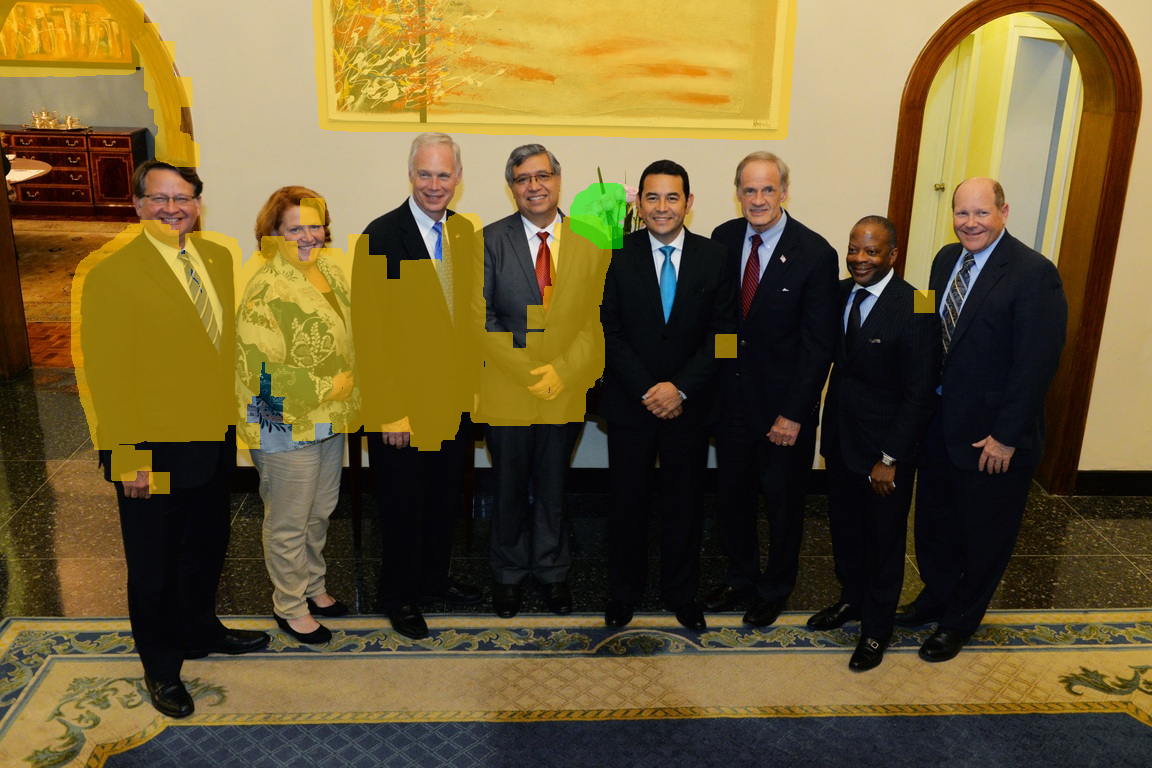

In [ ]:
import numpy as np
from PIL import ImageFilter
from transformers import (Owlv2Processor, Owlv2ForObjectDetection,
                          SamModel, SamProcessor)

od_proc = Owlv2Processor.from_pretrained("google/owlv2-base-patch16-ensemble")
od = Owlv2ForObjectDetection.from_pretrained("google/owlv2-base-patch16-ensemble").to("cuda")

def detectar(frases, umbral=0.15):
    inp = od_proc(text=[frases], images=img, return_tensors="pt").to("cuda")
    with torch.no_grad():
        out = od(**inp)
    tam = torch.tensor([[H, W]])
    try:
        r = od_proc.post_process_grounded_object_detection(out, threshold=umbral, target_sizes=tam)[0]
    except AttributeError:
        r = od_proc.post_process_object_detection(out, threshold=umbral, target_sizes=tam)[0]
    return [(r["scores"][i].item(), [int(v) for v in r["boxes"][i].tolist()])
            for i in range(len(r["scores"]))]

def caja_a_mascara(c):
    m = np.zeros((H, W), bool)
    x0, y0, x1, y1 = [max(0, v) for v in c]
    m[y0:min(H, y1), x0:min(W, x1)] = True
    return m

# --- zona prohibida: caras y manos, con margen ---
PROHIBIDO = np.zeros((H, W), bool)
caras = detectar(["a human face", "a human hand"], 0.1)
for _, (x0, y0, x1, y1) in caras:
    mx, my = (x1 - x0)//3, (y1 - y0)//3
    PROHIBIDO |= caja_a_mascara([x0 - mx, y0 - my, x1 + mx, y1 + my])
print(f"caras y manos detectadas: {len(caras)} → zona prohibida {PROHIBIDO.mean()*100:.1f} % de la imagen")
if not caras:
    print("AVISO: no detectó ninguna cara. Revisa la vista previa antes de generar.")

PERSONAS = [c for _, c in detectar(["a person"], 0.2)]
print(f"personas detectadas: {len(PERSONAS)}")

sam = SamModel.from_pretrained("facebook/sam-vit-base").to("cuda")
sam_proc = SamProcessor.from_pretrained("facebook/sam-vit-base")

def segmentar(caja):
    inp = sam_proc(img, input_boxes=[[caja]], return_tensors="pt").to("cuda")
    with torch.no_grad():
        out = sam(**inp)
    m = sam_proc.image_processor.post_process_masks(
        out.pred_masks.cpu(), inp["original_sizes"].cpu(), inp["reshaped_input_sizes"].cpu())
    return m[0][0, out.iou_scores[0, 0].argmax().item()].numpy()

# bandas provisionales de área relativa (%)
BANDAS = {"persona": {"obvio": (40, 100), "normal": (8, 40), "sutil": (0.5, 8)},
          "escena":  {"obvio": (3, 100),  "normal": (0.8, 3), "sutil": (0.1, 0.8)}}

def clasificar(area_rel, ref):
    for nivel, (lo, hi) in BANDAS[ref].items():
        if lo <= area_rel <= hi:
            return nivel
    return None

EDICIONES, RECHAZADAS = [], []
for e in propuesta["ediciones"]:
    det = detectar([e["objeto"]], 0.1)
    if not det:
        RECHAZADAS.append((e["tamano"], e["objeto"], "OWLv2 no lo encontró")); continue

    # unión de todas las cajas detectadas, expandida un 10 %
    cajas = [c for _, c in det]
    x0 = min(c[0] for c in cajas); y0 = min(c[1] for c in cajas)
    x1 = max(c[2] for c in cajas); y1 = max(c[3] for c in cajas)
    mx, my = int((x1-x0)*0.1), int((y1-y0)*0.1)
    caja = [max(0, x0-mx), max(0, y0-my), min(W, x1+mx), min(H, y1+my)]

    cruda = segmentar(caja)
    dil = np.asarray(Image.fromarray((cruda*255).astype(np.uint8)).filter(ImageFilter.MaxFilter(21))) > 0
    solape = (dil & PROHIBIDO).sum() / max(1, dil.sum())
    if solape > 0.10:
        RECHAZADAS.append((e["tamano"], e["objeto"], f"toca cara o mano ({solape*100:.0f} %)")); continue
    mascara = dil & ~PROHIBIDO
    if mascara.sum() < 200:
        RECHAZADAS.append((e["tamano"], e["objeto"], "máscara demasiado pequeña")); continue

    ys, xs = np.where(mascara)
    cx, cy = xs.mean(), ys.mean()
    dentro = [p for p in PERSONAS if p[0] <= cx <= p[2] and p[1] <= cy <= p[3]]
    if dentro:
        p = min(dentro, key=lambda b: (b[2]-b[0])*(b[3]-b[1]))
        ref_area, ref = (p[2]-p[0])*(p[3]-p[1]), "persona"
    else:
        ref_area, ref = W*H, "escena"

    area_img = mascara.sum()/(W*H)*100
    area_rel = mascara.sum()/ref_area*100
    nivel = clasificar(area_rel, ref)
    if nivel is None:
        RECHAZADAS.append((e["tamano"], e["objeto"], f"área relativa {area_rel:.2f} % fuera de todas las bandas")); continue

    EDICIONES.append(dict(
        nivel=nivel, tamano=e["tamano"], objeto=e["objeto"], caja=caja, ref=ref,
        mascara=mascara, area_img=area_img, area_rel=area_rel,
        prompt=f'{e["cambio"]}, photorealistic photograph, natural indoor lighting',
        negativo=f'{e["evitar"]}, cartoon, distorted, blurry, extra limbs, extra fingers'))

for t, o, motivo in RECHAZADAS:
    print(f"RECHAZADA [{t}] {o}: {motivo}")

niveles = [c["nivel"] for c in EDICIONES]
if len(set(niveles)) < len(niveles):
    print(f"AVISO: dos ediciones cayeron en el mismo nivel {niveles}")

vista = img.copy()
rojo = Image.new("RGB", img.size, (255, 0, 0))
vista = Image.composite(rojo, vista, Image.fromarray((PROHIBIDO*70).astype(np.uint8)))
colores = {"obvio": (255, 200, 0), "normal": (0, 160, 255), "sutil": (0, 255, 0)}
for c in EDICIONES:
    capa = Image.new("RGB", img.size, colores[c["nivel"]])
    vista = Image.composite(capa, vista, Image.fromarray((c["mascara"]*140).astype(np.uint8)))
    print(f'{c["tamano"]:8s} → {c["nivel"]:6s} | {c["objeto"][:28]:28s} | ref {c["ref"]:7s} '
          f'| área imagen {c["area_img"]:5.2f}% | área relativa {c["area_rel"]:6.2f}%')
vista.save(f"{SALIDA}/{PAR}_revision_mascaras.png")
display(vista)

del od, sam
torch.cuda.empty_cache()

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

obvio  | red necktie              | área rel  11.21% | cambio visible  2.86% FUERA DE RANGO | fuera de máscara 0


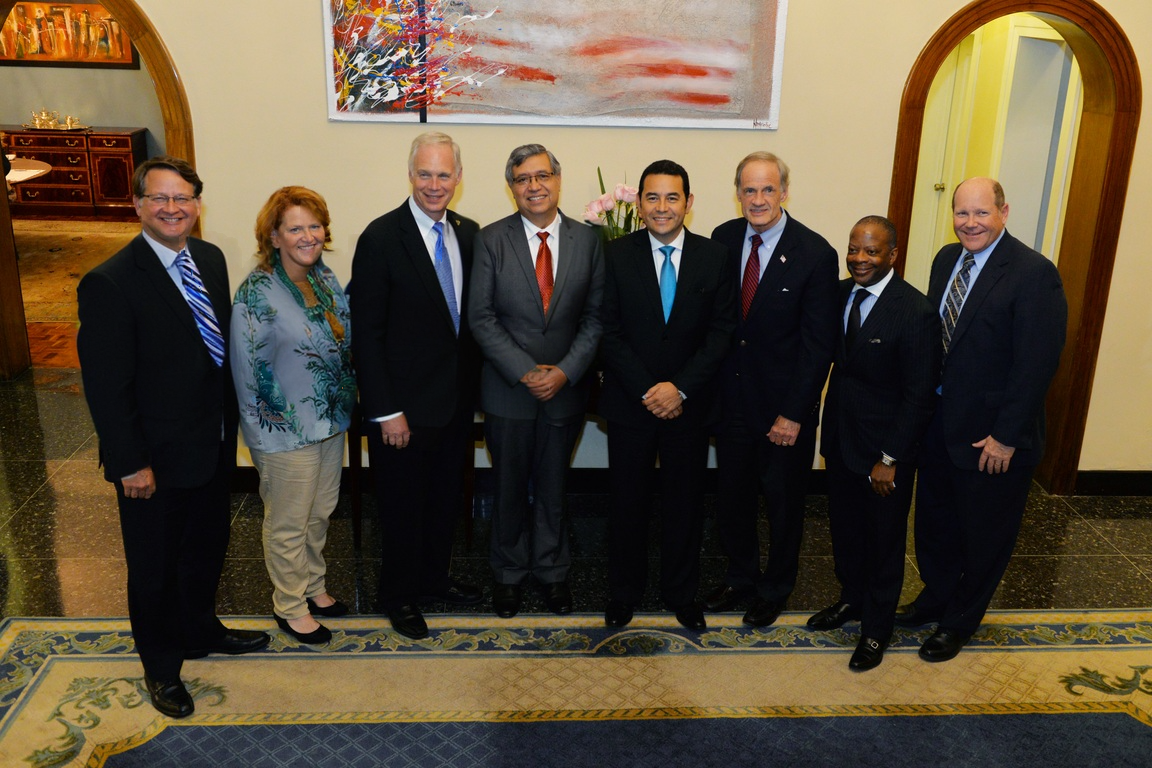

  0%|          | 0/39 [00:00<?, ?it/s]

sutil  | pink flowers in vase     | área rel   0.34% | cambio visible  0.13% OK | fuera de máscara 0


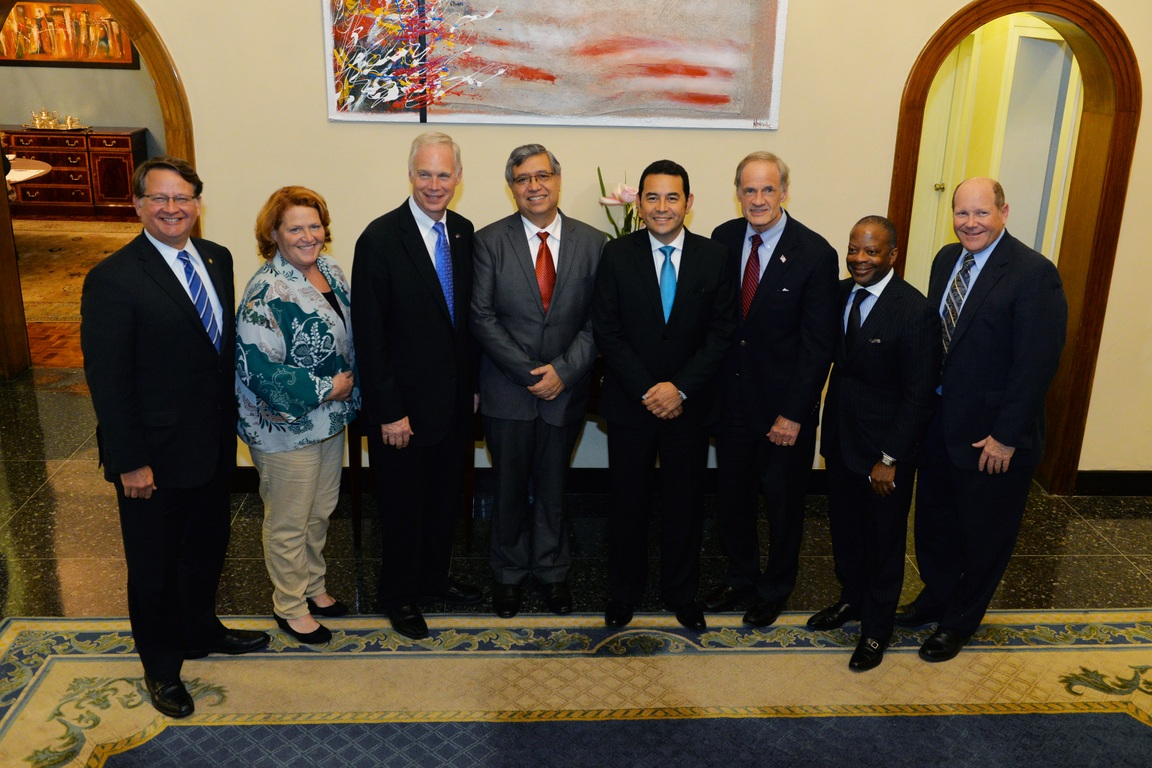

  0%|          | 0/39 [00:00<?, ?it/s]

obvio  | abstract art on wall     | área rel   9.08% | cambio visible  7.54% OK | fuera de máscara 0


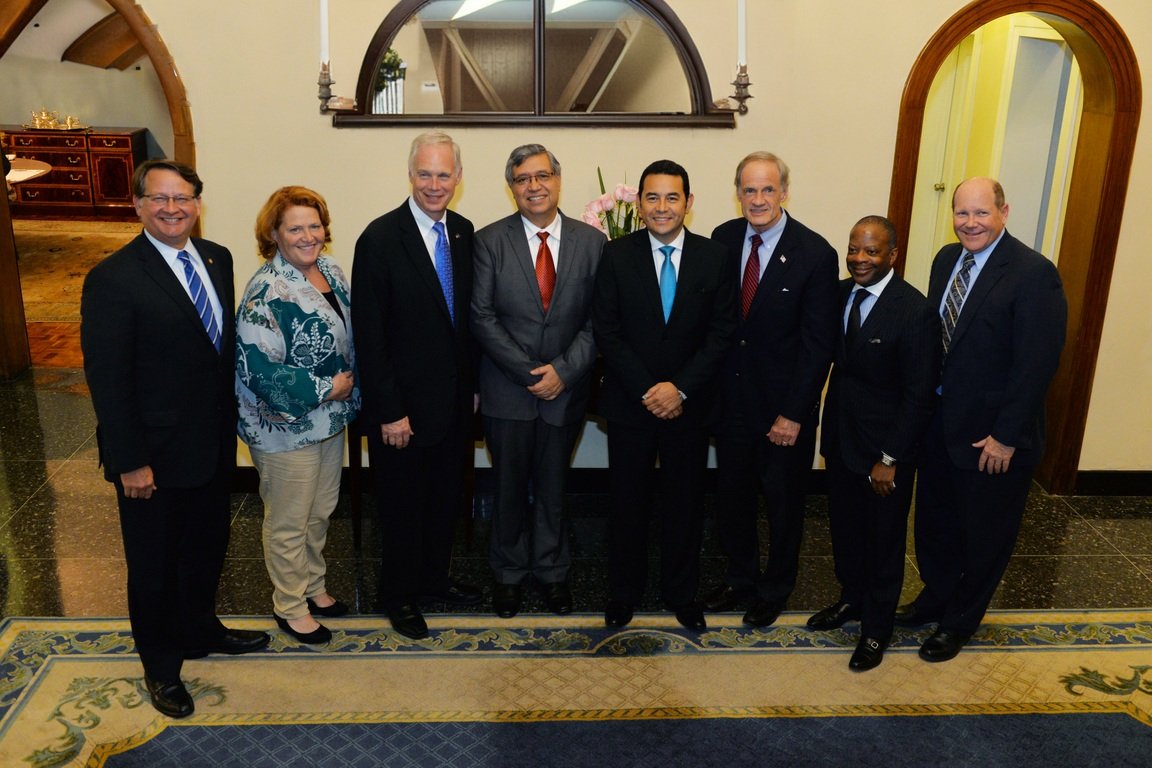

In [ ]:
from diffusers import AutoPipelineForInpainting
from skimage.color import rgb2lab, deltaE_ciede2000

pipe = AutoPipelineForInpainting.from_pretrained(
    "diffusers/stable-diffusion-xl-1.0-inpainting-0.1", torch_dtype=torch.float16).to("cuda")

real_np  = np.asarray(img)
lab_real = rgb2lab(real_np)
RANGO_CAMBIO = {"obvio": (3, 20), "normal": (0.4, 2), "sutil": (0.05, 0.4)}

registro = []
for c in EDICIONES:
    nombre   = c["nivel"]
    pequeno  = c["area_img"] < 1.0
    mask_pil = Image.fromarray((c["mascara"] * 255).astype(np.uint8))
    suave    = mask_pil.filter(ImageFilter.GaussianBlur(3))

    salida = pipe(
        prompt=c["prompt"], negative_prompt=c["negativo"],
        image=img, mask_image=mask_pil, width=W, height=H,
        num_inference_steps=40,
        guidance_scale=13.0 if pequeno else 11.0,
        strength=0.99,
        padding_mask_crop=64 if pequeno else 32,
        generator=torch.Generator("cuda").manual_seed(SEMILLA),
    ).images[0]
    compuesta = pipe.image_processor.apply_overlay(suave, img, salida).convert("RGB")
    comp_np   = np.asarray(compuesta)

    cambio = (deltaE_ciede2000(lab_real, rgb2lab(comp_np)) > 10).mean() * 100
    fuera  = np.abs(comp_np.astype(int) - real_np.astype(int))[np.asarray(suave) == 0].max()
    lo, hi = RANGO_CAMBIO[nombre]
    ok_c   = lo <= cambio <= hi

    compuesta.save(f"{SALIDA}/{PAR}_compuesta_{nombre}.png")
    compuesta.save(f"{SALIDA}/{PAR}_{nombre}.jpg", quality=CALIDAD_JPEG)
    mask_pil.save(f"{SALIDA}/{PAR}_mascara_{nombre}.png")

    registro.append({k: c[k] for k in ("nivel", "tamano", "objeto", "caja", "ref",
                                       "area_img", "area_rel", "prompt", "negativo")}
                    | {"cambio_visible": round(cambio, 3), "fuera_de_mascara": int(fuera),
                       "semilla": SEMILLA, "modelo": "sdxl-1.0-inpainting-0.1"})

    print(f'{nombre:6s} | {c["objeto"][:24]:24s} | área rel {c["area_rel"]:6.2f}% '
          f'| cambio visible {cambio:5.2f}% {"OK" if ok_c else "FUERA DE RANGO"} '
          f'| fuera de máscara {fuera}')
    display(compuesta)

with open(f"{SALIDA}/{PAR}_registro.json", "w", encoding="utf-8") as f:
    json.dump(registro, f, indent=2, ensure_ascii=False)